# E0: label-free pose diagnostics (inference only)

Runs ViTPose-L SwimXYZ and the **pretrained** YOLO11s-pose on all 5,613 frames of `datasets (1).zip`, each on the
frame and on its mirrored copy. Then it measures, per keypoint: coverage, flip consistency, agreement between the two
models, frame-to-frame jitter, whether confidence predicts agreement, and how many keypoints would survive as E1
pseudo-labels.

**Nothing is trained. There are no labels, so nothing here is accuracy.** Results are saved to
`MyDrive/pose_baseline/e0/`. The prediction run is resumable: if Colab disconnects, re-run cells 0-3 and then cell 5.
Plan: see `docs/POSE_SELF_SUPERVISED_RESEARCH.md`.


## 0. Drive and inputs

In [93]:
# 0. Drive, paths, inputs
from google.colab import drive
drive.mount('/content/drive')
from pathlib import Path
DRIVE = Path('/content/drive/MyDrive')
OUTD = DRIVE / 'pose_baseline'
ONNX = OUTD / 'models' / 'vitpose-l-swimxyz-mv.onnx'
YOLO_PT = OUTD / 'models' / 'yolo11s-pose.pt'
DS_ZIP = DRIVE / 'datasets (1).zip'
E0 = OUTD / 'e0'
E0.mkdir(exist_ok=True)
for f in (ONNX, YOLO_PT, DS_ZIP):
    assert f.is_file(), f'missing: {f}'
    print('OK', f.name, round(f.stat().st_size / 1e6, 1), 'MB')
!nvidia-smi --query-gpu=name,memory.total --format=csv


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
OK vitpose-l-swimxyz-mv.onnx 1234.4 MB
OK yolo11s-pose.pt 20.4 MB
OK datasets (1).zip 1600.7 MB
name, memory.total [MiB]
Tesla T4, 15360 MiB


## 1. Install

In [94]:
# 1. Install
!pip -q install onnxruntime-gpu ultralytics
import ultralytics, onnxruntime
print('ultralytics', ultralytics.__version__, '| onnxruntime', onnxruntime.__version__, onnxruntime.get_available_providers())
!mkdir -p /content/pose_tools


ultralytics 8.4.220 | onnxruntime 1.32.0 ['TensorrtExecutionProvider', 'CUDAExecutionProvider', 'CPUExecutionProvider']


## 2. Tools (generated from `python_scripts/pose/`)

In [95]:
%%writefile /content/pose_tools/pose_common.py
"""Shared helpers for the pose proposal / zero-shot tools (no project imports).

Top-down model contract (from the ViTPose-L SwimXYZ model card): input (N, 3, 256, 192) float32,
ImageNet-normalised RGB crop; output (N, 17, 64, 48) heatmaps in COCO-17 order.
Pure-numpy parts (box->crop parameters, heatmap decoding, PCK) are testable without weights.
"""
from __future__ import annotations

import math
from typing import Any

import numpy as np

COCO17 = ["nose", "left_eye", "right_eye", "left_ear", "right_ear", "left_shoulder", "right_shoulder",
          "left_elbow", "right_elbow", "left_wrist", "right_wrist", "left_hip", "right_hip",
          "left_knee", "right_knee", "left_ankle", "right_ankle"]
UPPER_BODY = [0, 5, 6, 7, 8, 9, 10]  # nose, shoulders, elbows, wrists
COCO_SKELETON = [[16, 14], [14, 12], [17, 15], [15, 13], [12, 13], [6, 12], [7, 13], [6, 7], [6, 8],
                 [7, 9], [8, 10], [9, 11], [2, 3], [1, 2], [1, 3], [2, 4], [3, 5], [4, 6], [5, 7]]
IN_W, IN_H = 192, 256
MEAN = np.array([0.485, 0.456, 0.406], dtype=np.float32)
STD = np.array([0.229, 0.224, 0.225], dtype=np.float32)


def crop_params(box_xyxy: tuple[float, float, float, float], scale: float = 1.25) -> tuple[float, float, float]:
    """Return (x0, y0, s) of the crop window: window covers IN_W/s x IN_H/s pixels, box centred, padded."""
    x1, y1, x2, y2 = box_xyxy
    cx, cy = (x1 + x2) / 2, (y1 + y2) / 2
    bw, bh = max(x2 - x1, 1.0) * scale, max(y2 - y1, 1.0) * scale
    if bw / bh > IN_W / IN_H:
        bh = bw * IN_H / IN_W
    else:
        bw = bh * IN_W / IN_H
    s = IN_W / bw
    return cx - bw / 2, cy - bh / 2, s


def preprocess(frame_bgr: np.ndarray, box_xyxy: tuple[float, float, float, float]
               ) -> tuple[np.ndarray, tuple[float, float, float]]:
    import cv2  # lazy: Colab has it

    x0, y0, s = crop_params(box_xyxy)
    m = np.array([[s, 0, -x0 * s], [0, s, -y0 * s]], dtype=np.float32)
    crop = cv2.warpAffine(frame_bgr, m, (IN_W, IN_H), flags=cv2.INTER_LINEAR,
                          borderMode=cv2.BORDER_CONSTANT, borderValue=(0, 0, 0))
    rgb = crop[:, :, ::-1].astype(np.float32) / 255.0
    rgb = (rgb - MEAN) / STD
    return rgb.transpose(2, 0, 1)[None], (x0, y0, s)


def decode_heatmaps(hm: np.ndarray, params: tuple[float, float, float]) -> np.ndarray:
    """hm: (17, H, W) -> (17, 3) [x, y, score] in image pixels (argmax, +quarter-pixel shift)."""
    k, h, w = hm.shape
    x0, y0, s = params
    out = np.zeros((k, 3), dtype=np.float32)
    for i in range(k):
        flat = int(np.argmax(hm[i]))
        iy, ix = divmod(flat, w)
        score = float(hm[i, iy, ix])
        fx, fy = float(ix), float(iy)
        if 0 < ix < w - 1:
            fx += 0.25 * np.sign(hm[i, iy, ix + 1] - hm[i, iy, ix - 1])
        if 0 < iy < h - 1:
            fy += 0.25 * np.sign(hm[i, iy + 1, ix] - hm[i, iy - 1, ix])
        cx, cy = (fx + 0.5) * IN_W / w, (fy + 0.5) * IN_H / h  # crop pixels
        out[i] = (cx / s + x0, cy / s + y0, score)
    return out


class OnnxVitPose:
    """Top-down ONNX pose model (ViTPose-L SwimXYZ export). Input name is read from the graph."""

    def __init__(self, path: str, providers: list[str] | None = None) -> None:
        import onnxruntime as ort

        self.sess = ort.InferenceSession(path, providers=providers or ["CUDAExecutionProvider",
                                                                         "CPUExecutionProvider"])
        self.input_name = self.sess.get_inputs()[0].name

    def predict(self, frame_bgr: np.ndarray, boxes: list[tuple[float, float, float, float]]) -> list[np.ndarray]:
        res = []
        for b in boxes:
            x, params = preprocess(frame_bgr, b)
            hm = self.sess.run(None, {self.input_name: x})[0][0]
            res.append(decode_heatmaps(hm, params))
        return res


def iou(a: tuple[float, ...], b: tuple[float, ...]) -> float:
    ix = max(0.0, min(a[2], b[2]) - max(a[0], b[0]))
    iy = max(0.0, min(a[3], b[3]) - max(a[1], b[1]))
    inter = ix * iy
    union = (a[2] - a[0]) * (a[3] - a[1]) + (b[2] - b[0]) * (b[3] - b[1]) - inter
    return inter / union if union > 0 else 0.0


def pck(pred: np.ndarray, gt: np.ndarray, box_xyxy: tuple[float, ...], thr: float,
        idx: list[int] | None = None) -> tuple[int, int]:
    """(correct, total) over GT keypoints with visibility > 0. Normaliser: longer side of the GT box."""
    norm = max(box_xyxy[2] - box_xyxy[0], box_xyxy[3] - box_xyxy[1], 1.0)
    ok = tot = 0
    for i in idx if idx is not None else range(len(gt)):
        if gt[i][2] <= 0:
            continue
        tot += 1
        if math.hypot(pred[i][0] - gt[i][0], pred[i][1] - gt[i][1]) <= thr * norm:
            ok += 1
    return ok, tot


def confident_upper(pred: np.ndarray, min_conf: float = 0.5) -> int:
    return int(sum(1 for i in UPPER_BODY if pred[i][2] >= min_conf))


def as_info(**kw: Any) -> dict[str, Any]:
    return kw


Overwriting /content/pose_tools/pose_common.py


In [96]:
%%writefile /content/pose_tools/e0_diagnostics.py
"""E0: label-free pose diagnostics (inference only, no training, no labels).

Two modes:
  --run      ViTPose-L SwimXYZ (top-down, on the dataset box) and YOLO11s-pose (full frame, matched to the box) on
             every frame and on its horizontally flipped copy. Appends one JSON line per frame (resumable).
  --analyze  Per-keypoint coverage, flip consistency, cross-model agreement, temporal jitter, confidence-vs-agreement,
             consensus coverage (E1 feasibility) and the most disputed held-out frames (E3 candidates).
All numbers are consistency / agreement measures. None of them is accuracy: there is no ground truth here.

Distances are normalised by the longer side of the dataset box. "ok" means confidence >= --conf.
Held-out = frame-index blocks 2, 13, 15, 16 (block size 3000), the real_val blocks of the pose set: never train on them.
"""
from __future__ import annotations

import argparse
import json
import re
import time
from pathlib import Path

import numpy as np

from pose_common import COCO17, UPPER_BODY

FLIP_IDX = [0, 2, 1, 4, 3, 6, 5, 8, 7, 10, 9, 12, 11, 14, 13, 16, 15]
LOWER_BODY = [11, 12, 13, 14, 15, 16]
HELDOUT_BLOCKS = {2, 13, 15, 16}
BLOCK = 3000
# Proposed thresholds (fractions of box size); documented in the report, not tuned on any labels.
CROSS_OK, FLIP_OK, JUMP_OK, DISPUTE = 0.10, 0.10, 0.25, 0.20


def frame_idx(p: Path) -> int:
    return int(re.search(r"(\d+)$", p.stem).group(1))


def unflip(kp: np.ndarray, width: int) -> np.ndarray:
    out = kp[FLIP_IDX].copy()
    out[:, 0] = width - out[:, 0]
    return out


# --------------------------------------------------------------------------------------------- inference
def run(root: Path, onnx: str, yolo_w: str, out: Path, limit: int | None) -> None:
    import cv2
    from ultralytics import YOLO

    from pose_common import OnnxVitPose, iou

    vit = OnnxVitPose(onnx)
    yolo = YOLO(yolo_w)
    done = set()
    if out.is_file():
        done = {json.loads(ln)["file"] for ln in out.read_text().splitlines() if ln.strip()}
    imgs = sorted([p for sp in ("train", "val") for p in (root / "images" / sp).glob("*.jpg")], key=frame_idx)
    if limit:
        imgs = imgs[:limit]
    todo = [p for p in imgs if p.name not in done]
    print(f"{len(imgs)} frames, {len(done)} already done, {len(todo)} to run")

    def yolo_match(res, box):
        if res.keypoints is None or len(res.boxes) == 0:
            return None
        ious = [iou(tuple(b), box) for b in res.boxes.xyxy.cpu().numpy()]
        i = int(np.argmax(ious))
        if ious[i] < 0.3:
            return None
        return np.concatenate([res.keypoints.xy[i].cpu().numpy(), res.keypoints.conf[i].cpu().numpy()[:, None]], 1)

    t0 = time.time()
    with open(out, "a", encoding="utf-8") as f:
        for n, p in enumerate(todo, 1):
            img = cv2.imread(str(p))
            h, w = img.shape[:2]
            t = (p.parent.parent.parent / "labels" / p.parent.name / (p.stem + ".txt")).read_text().split()
            cx, cy, bw, bh = (float(v) for v in t[1:5])
            box = ((cx - bw / 2) * w, (cy - bh / 2) * h, (cx + bw / 2) * w, (cy + bh / 2) * h)
            fimg = np.ascontiguousarray(img[:, ::-1])
            fbox = (w - box[2], box[1], w - box[0], box[3])
            kv = vit.predict(img, [box])[0]
            kvf = unflip(vit.predict(fimg, [fbox])[0], w)
            r = yolo.predict([img, fimg], verbose=False)
            ky = yolo_match(r[0], box)
            kyf = yolo_match(r[1], fbox)
            kyf = unflip(kyf, w) if kyf is not None else None
            idx = frame_idx(p)
            rec = {"file": p.name, "idx": idx, "folder": p.parent.name, "block": idx // BLOCK,
                   "heldout": idx // BLOCK in HELDOUT_BLOCKS, "box": [round(v, 1) for v in box], "W": w, "H": h,
                   "vit": np.round(kv, 3).tolist(), "vit_f": np.round(kvf, 3).tolist(),
                   "yolo": None if ky is None else np.round(ky, 3).tolist(),
                   "yolo_f": None if kyf is None else np.round(kyf, 3).tolist()}
            f.write(json.dumps(rec) + "\n")
            if n % 250 == 0 or n == len(todo):
                f.flush()
                el = time.time() - t0
                print(f"  {n}/{len(todo)}  {el / n * 1000:.0f} ms/frame  eta {el / n * (len(todo) - n) / 60:.1f} min")


# --------------------------------------------------------------------------------------------- analysis
def analyze(pred: Path, out_dir: Path, conf: float, root: Path | None) -> dict:
    recs = sorted((json.loads(ln) for ln in pred.read_text().splitlines() if ln.strip()), key=lambda r: r["idx"])
    for r in recs:
        for m in ("vit", "vit_f", "yolo", "yolo_f"):
            r[m] = None if r[m] is None else np.array(r[m], dtype=float)
        x1, y1, x2, y2 = r["box"]
        r["size"] = max(x2 - x1, y2 - y1, 1.0)
        r["c"] = np.array([(x1 + x2) / 2, (y1 + y2) / 2])
    K = 17

    def ok(k, i):
        return k is not None and k[i][2] >= conf

    def d(a, b, i, s):
        return float(np.hypot(*(a[i][:2] - b[i][:2]))) / s

    cov = {m: np.zeros(K) for m in ("vit", "yolo")}
    flip = {m: [[] for _ in range(K)] for m in ("vit", "yolo")}
    cross = [[] for _ in range(K)]
    for r in recs:
        for i in range(K):
            for m in ("vit", "yolo"):
                if ok(r[m], i):
                    cov[m][i] += 1
                    if ok(r[m + "_f"], i):
                        flip[m][i].append(d(r[m], r[m + "_f"], i, r["size"]))
            if ok(r["vit"], i) and ok(r["yolo"], i):
                cross[i].append(d(r["vit"], r["yolo"], i, r["size"]))
    n = len(recs)

    # runs of near-consecutive frames (gap <= 3) -> jitter = second difference after removing box-centre motion
    runs, cur = [], [recs[0]]
    for a, b in zip(recs, recs[1:]):
        if b["idx"] - a["idx"] <= 3:
            cur.append(b)
        else:
            runs.append(cur)
            cur = [b]
    runs.append(cur)
    runs = [r for r in runs if len(r) >= 3]
    jit = {m: [[] for _ in range(K)] for m in ("vit", "yolo")}
    for run_ in runs:
        for a, b, c in zip(run_, run_[1:], run_[2:]):
            for m in ("vit", "yolo"):
                for i in range(K):
                    if ok(a[m], i) and ok(b[m], i) and ok(c[m], i):
                        pa, pb, pc = a[m][i][:2] - a["c"], b[m][i][:2] - b["c"], c[m][i][:2] - c["c"]
                        jit[m][i].append(float(np.hypot(*(pa - 2 * pb + pc))) / b["size"])

    # confidence vs agreement: does a confident point agree with the other model?
    calib = {}
    for m, o in (("vit", "yolo"), ("yolo", "vit")):
        bins = {"0.5-0.7": [], "0.7-0.9": [], ">=0.9": []}
        for r in recs:
            if r[m] is None or r[o] is None:
                continue
            for i in range(K):
                c_ = r[m][i][2]
                if c_ < conf or r[o][i][2] < 0.3:
                    continue
                key = "0.5-0.7" if c_ < 0.7 else ("0.7-0.9" if c_ < 0.9 else ">=0.9")
                bins[key].append(d(r[m], r[o], i, r["size"]) <= CROSS_OK)
        calib[m] = {k: (round(float(np.mean(v)), 3), len(v)) for k, v in bins.items() if v}

    # consensus (E1 candidate labels) and disputes
    prev = {}
    by_idx = {r["idx"]: r for r in recs}
    for r in recs:
        p = next((by_idx[r["idx"] - g] for g in (1, 2, 3) if r["idx"] - g in by_idx), None)
        prev[r["idx"]] = p
    cons_cov = np.zeros(K)
    n_train = 0
    cons_per_frame, disputes = [], []
    for r in recs:
        npass, ndis = 0, 0
        for i in range(K):
            if ok(r["vit"], i) and ok(r["yolo"], i):
                dc = d(r["vit"], r["yolo"], i, r["size"])
                if dc > DISPUTE:
                    ndis += 1
                good = dc <= CROSS_OK
                for m in ("vit", "yolo"):
                    good = good and ok(r[m + "_f"], i) and d(r[m], r[m + "_f"], i, r["size"]) <= FLIP_OK
                p = prev[r["idx"]]
                if good and p is not None and ok(p["vit"], i):
                    jump = float(np.hypot(*((r["vit"][i][:2] - r["c"]) - (p["vit"][i][:2] - p["c"])))) / r["size"]
                    good = jump <= JUMP_OK
                if good:
                    npass += 1
                    if not r["heldout"]:
                        cons_cov[i] += 1
        if not r["heldout"]:
            n_train += 1
            cons_per_frame.append(npass)
        disputes.append((ndis, r))
    cons_cov /= max(n_train, 1)
    cpf = np.array(cons_per_frame) if cons_per_frame else np.zeros(1)
    lower_cov = float(cons_cov[LOWER_BODY].mean())
    feasible = float(np.median(cpf)) >= 8 and lower_cov >= 0.30

    out_dir.mkdir(parents=True, exist_ok=True)
    rows = ["keypoint,cov_vit,cov_yolo,flip_med_vit,flip_med_yolo,cross_med,cross_le_0.10,"
            "jitter_med_vit,jitter_med_yolo,consensus_cov_train"]

    def med(x):
        return f"{np.median(x):.3f}" if x else ""

    for i, nm in enumerate(COCO17):
        cr = cross[i]
        rows.append(",".join([nm, f"{cov['vit'][i] / n:.3f}", f"{cov['yolo'][i] / n:.3f}", med(flip["vit"][i]),
                              med(flip["yolo"][i]), med(cr),
                              f"{np.mean(np.array(cr) <= CROSS_OK):.3f}" if cr else "", med(jit["vit"][i]),
                              med(jit["yolo"][i]), f"{cons_cov[i]:.3f}"]))
    (out_dir / "e0_per_keypoint.csv").write_text("\n".join(rows) + "\n", encoding="utf-8")

    held = sorted([x for x in disputes if x[1]["heldout"]], key=lambda x: -x[0])[:30]
    (out_dir / "e0_disputed_heldout.csv").write_text(
        "file,idx,block,disputed_keypoints\n" + "".join(f"{r['file']},{r['idx']},{r['block']},{k}\n" for k, r in held),
        encoding="utf-8")

    no_yolo = sum(r["yolo"] is None for r in recs)
    rep = [
        "E0 LABEL-FREE DIAGNOSTICS - consistency/agreement only, NOT accuracy",
        f"frames {n} (held-out {n - n_train}, training-eligible {n_train}); runs >= 3 frames: {len(runs)}; "
        f"YOLO found no matching person in {no_yolo} frames",
        f"thresholds: conf >= {conf}; agree <= {CROSS_OK}; flip <= {FLIP_OK}; jump <= {JUMP_OK}; "
        f"dispute > {DISPUTE} (fractions of box size)",
        "",
        "per keypoint: see e0_per_keypoint.csv (coverage, flip error, cross-model distance, jitter, consensus)",
        "",
        "confidence vs agreement with the other model (fraction within the agree threshold, count):",
        f"  ViTPose: {calib.get('vit')}",
        f"  YOLO:    {calib.get('yolo')}",
        "",
        f"consensus keypoints per training-eligible frame: median {np.median(cpf):.1f}, mean {cpf.mean():.1f} of 17",
        f"consensus coverage upper body {cons_cov[UPPER_BODY].mean():.2f}, lower body {lower_cov:.2f}",
        f"E1 feasibility (proposed rule: median >= 8 AND lower body >= 0.30): {'FEASIBLE' if feasible else 'NOT FEASIBLE'}",
        "",
        f"most disputed held-out frames (E3 candidates): e0_disputed_heldout.csv (top {len(held)})",
    ]
    (out_dir / "e0_report.txt").write_text("\n".join(rep) + "\n", encoding="utf-8")
    print("\n".join(rep))
    print()
    print("\n".join(rows))

    if root is not None and held:
        sheet(root, held[:12], out_dir / "e0_disputed_heldout.jpg", conf)
    return {"feasible": feasible, "median_consensus": float(np.median(cpf)), "lower_cov": lower_cov}


def sheet(root: Path, items, path: Path, conf: float) -> None:
    import cv2

    sk = [(5, 7), (7, 9), (6, 8), (8, 10), (5, 6), (5, 11), (6, 12), (11, 12), (11, 13), (13, 15), (12, 14), (14, 16)]

    def draw(im, k, col):
        if k is None:
            return
        for a, b in sk:
            if k[a][2] >= conf and k[b][2] >= conf:
                cv2.line(im, tuple(int(v) for v in k[a][:2]), tuple(int(v) for v in k[b][:2]), col, 3)
        for x, y, c in k:
            if c >= conf:
                cv2.circle(im, (int(x), int(y)), 6, col, -1)

    tiles = []
    for _, r in items:
        p = next((root / "images" / sp / r["file"] for sp in ("train", "val")
                  if (root / "images" / sp / r["file"]).is_file()), None)
        if p is None:
            continue
        im = cv2.imread(str(p))
        draw(im, r["vit"], (0, 255, 255))   # ViTPose yellow
        draw(im, r["yolo"], (255, 0, 255))  # YOLO magenta
        cx, cy = (int(v) for v in r["c"])
        s = int(r["size"] * 0.8)
        crop = cv2.resize(im[max(0, cy - s):cy + s, max(0, cx - s):cx + s], (300, 300))
        cv2.putText(crop, r["file"][6:11], (5, 22), cv2.FONT_HERSHEY_SIMPLEX, 0.7, (255, 255, 255), 2)
        tiles.append(crop)
    while len(tiles) % 6:
        tiles.append(np.zeros((300, 300, 3), np.uint8))
    rows = [np.hstack(tiles[i:i + 6]) for i in range(0, len(tiles), 6)]
    cv2.imwrite(str(path), np.vstack(rows))
    print("saved", path, "(yellow = ViTPose, magenta = YOLO11s-pose)")


def main() -> int:
    ap = argparse.ArgumentParser(description=__doc__, formatter_class=argparse.RawDescriptionHelpFormatter)
    ap.add_argument("--run", action="store_true")
    ap.add_argument("--analyze", action="store_true")
    ap.add_argument("--root", type=Path, help="dataset root with images/{train,val} and labels/{train,val}")
    ap.add_argument("--onnx")
    ap.add_argument("--yolo")
    ap.add_argument("--pred", type=Path, required=True, help="predictions JSONL (written by --run, read by --analyze)")
    ap.add_argument("--out", type=Path, help="analysis output folder")
    ap.add_argument("--limit", type=int, help="only the first N frames (smoke test)")
    ap.add_argument("--conf", type=float, default=0.5)
    a = ap.parse_args()
    if a.run:
        run(a.root, a.onnx, a.yolo, a.pred, a.limit)
    if a.analyze:
        analyze(a.pred, a.out or a.pred.parent, a.conf, a.root)
    return 0


if __name__ == "__main__":
    raise SystemExit(main())


Writing /content/pose_tools/e0_diagnostics.py


## 3. Data

In [97]:
# 3. Unzip the 5,613-frame dataset locally (one zip copy; skipped if already there)
import shutil, zipfile
ROOT = Path('/content/pose_ds/datasets')
if not ROOT.is_dir():
    shutil.copyfile(DS_ZIP, '/content/pose_ds.zip')
    with zipfile.ZipFile('/content/pose_ds.zip') as z:
        z.extractall('/content/pose_ds')
print('frames:', sum(1 for _ in (ROOT / 'images').rglob('*.jpg')))


frames: 5613


## 4. Smoke test

In [98]:
# 4. Smoke test on 30 frames (separate file, deleted first). Check ms/frame before the full run.
SMOKE = Path('/content/e0_smoke.jsonl')
SMOKE.unlink(missing_ok=True)
!cd /content/pose_tools && python e0_diagnostics.py --run --root "{ROOT}" --onnx "{ONNX}" --yolo "{YOLO_PT}" --pred "{SMOKE}" --limit 30
import json
r = json.loads(SMOKE.read_text().splitlines()[0])
print('first record keys:', list(r)[:12], '| yolo found:', r['yolo'] is not None)


30 frames, 0 already done, 30 to run
  30/30  191 ms/frame  eta 0.0 min
first record keys: ['file', 'idx', 'folder', 'block', 'heldout', 'box', 'W', 'H', 'vit', 'vit_f', 'yolo', 'yolo_f'] | yolo found: True


## 5. Full prediction run

In [99]:
# 5. Full run on all frames -> Drive (resumable; about 10-30 min on a T4, estimate)
PRED = E0 / 'e0_predictions.jsonl'
!cd /content/pose_tools && python e0_diagnostics.py --run --root "{ROOT}" --onnx "{ONNX}" --yolo "{YOLO_PT}" --pred "{PRED}"
print('lines:', sum(1 for _ in open(PRED)))


5613 frames, 0 already done, 5613 to run
  250/5613  127 ms/frame  eta 11.3 min
  500/5613  122 ms/frame  eta 10.4 min
  750/5613  120 ms/frame  eta 9.7 min
  1000/5613  119 ms/frame  eta 9.1 min
  1250/5613  119 ms/frame  eta 8.6 min
  1500/5613  118 ms/frame  eta 8.1 min
  1750/5613  118 ms/frame  eta 7.6 min
  2000/5613  118 ms/frame  eta 7.1 min
  2250/5613  118 ms/frame  eta 6.6 min
  2500/5613  118 ms/frame  eta 6.1 min
  2750/5613  118 ms/frame  eta 5.6 min
  3000/5613  118 ms/frame  eta 5.1 min
  3250/5613  118 ms/frame  eta 4.6 min
  3500/5613  118 ms/frame  eta 4.1 min
  3750/5613  118 ms/frame  eta 3.6 min
  4000/5613  118 ms/frame  eta 3.2 min
  4250/5613  117 ms/frame  eta 2.7 min
  4500/5613  117 ms/frame  eta 2.2 min
  4750/5613  117 ms/frame  eta 1.7 min
  5000/5613  117 ms/frame  eta 1.2 min
  5250/5613  117 ms/frame  eta 0.7 min
  5500/5613  117 ms/frame  eta 0.2 min
  5613/5613  117 ms/frame  eta 0.0 min
lines: 5613


## 6. Analysis

In [100]:
# 6. Analysis -> e0_report.txt, e0_per_keypoint.csv, e0_disputed_heldout.csv, e0_disputed_heldout.jpg
!cd /content/pose_tools && python e0_diagnostics.py --analyze --root "{ROOT}" --pred "{PRED}" --out "{E0}"


E0 LABEL-FREE DIAGNOSTICS - consistency/agreement only, NOT accuracy
frames 5613 (held-out 620, training-eligible 4993); runs >= 3 frames: 74; YOLO found no matching person in 788 frames
thresholds: conf >= 0.5; agree <= 0.1; flip <= 0.1; jump <= 0.25; dispute > 0.2 (fractions of box size)

per keypoint: see e0_per_keypoint.csv (coverage, flip error, cross-model distance, jitter, consensus)

confidence vs agreement with the other model (fraction within the agree threshold, count):
  ViTPose: {'0.5-0.7': (0.387, 13839), '0.7-0.9': (0.672, 20353), '>=0.9': (0.918, 17573)}
  YOLO:    {'0.5-0.7': (0.411, 6054), '0.7-0.9': (0.401, 11874), '>=0.9': (0.697, 40434)}

consensus keypoints per training-eligible frame: median 4.0, mean 5.9 of 17
consensus coverage upper body 0.36, lower body 0.47
E1 feasibility (proposed rule: median >= 8 AND lower body >= 0.30): NOT FEASIBLE

most disputed held-out frames (E3 candidates): e0_disputed_heldout.csv (top 30)

keypoint,cov_vit,cov_yolo,flip_med_vit,fl

## 7. Disputed frames

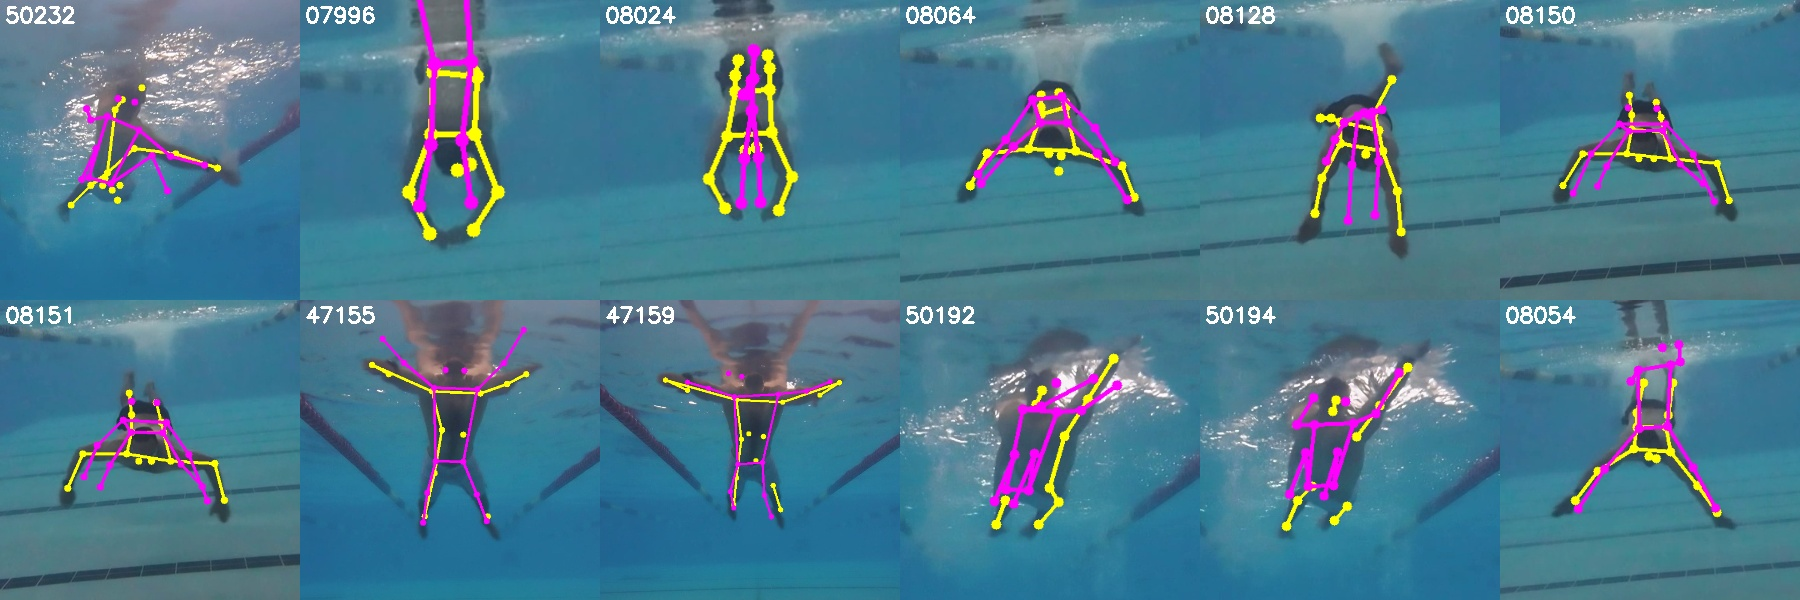

In [101]:
# 7. Most disputed held-out frames (yellow = ViTPose, magenta = YOLO11s-pose)
from IPython.display import Image, display
display(Image(str(E0 / 'e0_disputed_heldout.jpg')))


Paste the output of cell 6 and the image from cell 7. The E1 decision comes from the consensus lines; the disputed held-out frames are the E3 candidates.